In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        if (folder / "data" / "raw").is_dir():
            return folder
    raise FileNotFoundError("data/raw/ not found above " + str(start))

ROOT = find_project_root()
RAW_DIR, PROC_DIR, RESULTS_DIR = ROOT/"data"/"raw", ROOT/"data"/"processed", ROOT/"results"

with open(PROC_DIR / "preprocessing_config.json") as f:
    config = json.load(f)
feature_sensors = config["feature_sensors"]
WINDOW, CAP = 80, 130

col_names = (["unit", "cycle"] + [f"setting_{i}" for i in range(1, 4)]
             + [f"sensor_{i}" for i in range(1, 22)])
test = pd.read_csv(RAW_DIR / "test_FD001.txt", sep=r"\s+", header=None, names=col_names)
rul_test = pd.read_csv(RAW_DIR / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"])
train = pd.read_csv(PROC_DIR / "train_engineered.csv")[["unit", "cycle"] + feature_sensors + ["RUL"]]

print(len(feature_sensors), "sensors:", feature_sensors)
print("train:", train.shape, "| test:", test.shape, "| rul_test:", rul_test.shape)

14 sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
train: (20631, 17) | test: (13096, 26) | rul_test: (100, 1)


In [3]:
def _slope(a):
    x = np.arange(len(a)); xm = x.mean()
    return ((x - xm) * (a - a.mean())).sum() / ((x - xm) ** 2).sum()

def make_features(df, sensors, window):
    d = df.sort_values(["unit", "cycle"]).reset_index(drop=True)
    slope = (d.groupby("unit")[sensors].rolling(window, min_periods=2).apply(_slope, raw=True)
               .reset_index(level=0, drop=True)
               .add_suffix(f"_slope{window}").fillna(0.0))
    X = pd.concat([d[sensors], slope, d[["cycle"]]], axis=1)
    return X, d

X_train, d_train = make_features(train, feature_sensors, WINDOW)
y_train = d_train["RUL"].clip(upper=CAP)

print("train features:", X_train.shape)
print("NaNs:", int(X_train.isna().sum().sum()))
print("target range after cap:", y_train.min(), "to", y_train.max())

train features: (20631, 29)
NaNs: 0
target range after cap: 0 to 130


In [4]:
X_test, d_test = make_features(test, feature_sensors, WINDOW)
print("test features:", X_test.shape)        # expect (13096, 29)

# The features must not depend on the future: truncate engine 1 and recompute
e1 = test[test["unit"] == 1]
X_trunc, _ = make_features(e1.head(60), feature_sensors, WINDOW)
same = np.allclose(X_test[d_test["unit"] == 1].head(60).to_numpy(), X_trunc.to_numpy())
print("Features identical when the future is removed:", same)

model = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                     subsample=0.8, colsample_bytree=0.8,
                     device="cuda", random_state=42)
model.fit(X_train, y_train)
print("trained")

test features: (13096, 29)
Features identical when the future is removed: True
trained


In [5]:
def nasa_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)      # d > 0: predicted too much life
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

is_last = (d_test["cycle"] == d_test.groupby("unit")["cycle"].transform("max")).to_numpy()
last_units = d_test.loc[is_last, "unit"].tolist()
assert last_units == list(range(1, 101)), "engine order does not match RUL_FD001.txt"

pred = model.predict(X_test[is_last])
y_true = rul_test["RUL"].to_numpy()

print("Engines scored:", len(pred))
print("Test MAE :", round(mean_absolute_error(y_true, pred), 2))
print("Test RMSE:", round(float(np.sqrt(mean_squared_error(y_true, pred))), 2))
print("NASA score:", round(nasa_score(y_true, pred), 1))
print("Mean signed error (+ = over-predicts life):", round(float((pred - y_true).mean()), 2))

Engines scored: 100
Test MAE : 9.12
Test RMSE: 11.94
NASA score: 220.4
Mean signed error (+ = over-predicts life): -0.1


/home/dark/Projects/turbofan-predictive-maintenance/.venv/lib/python3.14/site-packages/xgboost/core.py:569: UserWarning: [16:07:48] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


             n  mean_signed   MAE
bucket                           
(0, 70]     14          5.1  12.2
(70, 130]   31          2.0  12.2
(130, 200]  47         -2.1   6.4
(200, 400]   8         -5.7   7.7

Worst 5 engines:
 unit  observed_cycles  true_RUL   pred_RUL  error     bucket
   67               71        77 113.500000   36.5  (70, 130]
   30              143       115  82.300003  -32.7 (130, 200]
    2               49        98 127.699997   29.7    (0, 70]
   50               74        79 107.800003   28.8  (70, 130]
   45              152       114  85.199997  -28.8 (130, 200]


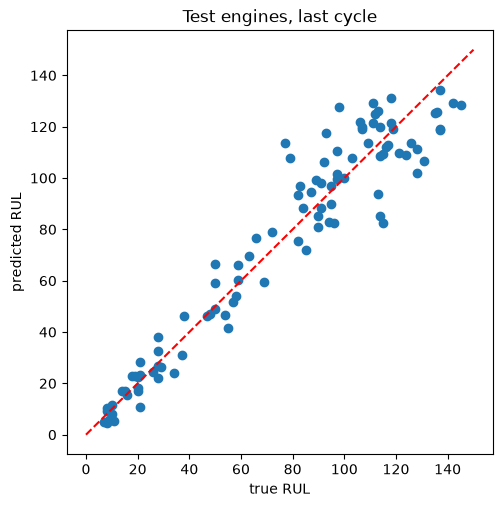

In [6]:
res = pd.DataFrame({"unit": last_units,
                    "observed_cycles": d_test.loc[is_last, "cycle"].to_numpy(),
                    "true_RUL": y_true, "pred_RUL": pred})
res["error"] = res["pred_RUL"] - res["true_RUL"]
res["bucket"] = pd.cut(res["observed_cycles"], [0, 70, 130, 200, 400])

print(res.groupby("bucket", observed=True)["error"]
         .agg(n="count", mean_signed="mean", MAE=lambda e: e.abs().mean()).round(1))
print("\nWorst 5 engines:")
print(res.reindex(res["error"].abs().sort_values(ascending=False).index).head(5).round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(res["true_RUL"], res["pred_RUL"])
lim = [0, max(res["true_RUL"].max(), res["pred_RUL"].max()) + 5]
ax.plot(lim, lim, "r--")
ax.set_xlabel("true RUL"); ax.set_ylabel("predicted RUL")
ax.set_title("Test engines, last cycle")
plt.show()

res.to_csv(RESULTS_DIR / "test_predictions_final.csv", index=False)

In [7]:
test_metrics = {
    "n_engines": 100,
    "MAE": 9.12,
    "RMSE": 11.94,
    "NASA_score": 220.4,
    "mean_signed_error": -0.1,
    "config": "14 raw sensors + slope80 + cycle, RUL cap 130, XGBoost, trained on all 100 training engines",
    "note": "single evaluation of the frozen configuration; test set not used for any modelling decision",
}
with open(RESULTS_DIR / "test_metrics_final.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

config["test_evaluation"] = test_metrics
with open(PROC_DIR / "preprocessing_config.json", "w") as f:
    json.dump(config, f, indent=2)
print("saved")

saved


In [8]:
(ROOT / "models").mkdir(exist_ok=True)
model.save_model(ROOT / "models" / "xgb_final.json")
print("saved:", sorted(p.name for p in (ROOT / "models").glob("*")))

saved: ['.gitkeep', 'xgb_final.json']


Max difference between SHAP reconstruction and prediction: 0.00014495849609375
cycle                10.68
sensor_11             5.90
sensor_4_slope80      3.95
sensor_12_slope80     3.63
sensor_4              3.44
sensor_9_slope80      2.34
sensor_20_slope80     2.29
sensor_14_slope80     2.20
sensor_15_slope80     2.18
sensor_11_slope80     2.15
sensor_12             2.09
sensor_17_slope80     2.02
sensor_7_slope80      1.80
sensor_21_slope80     1.45
sensor_7              1.43
dtype: float32


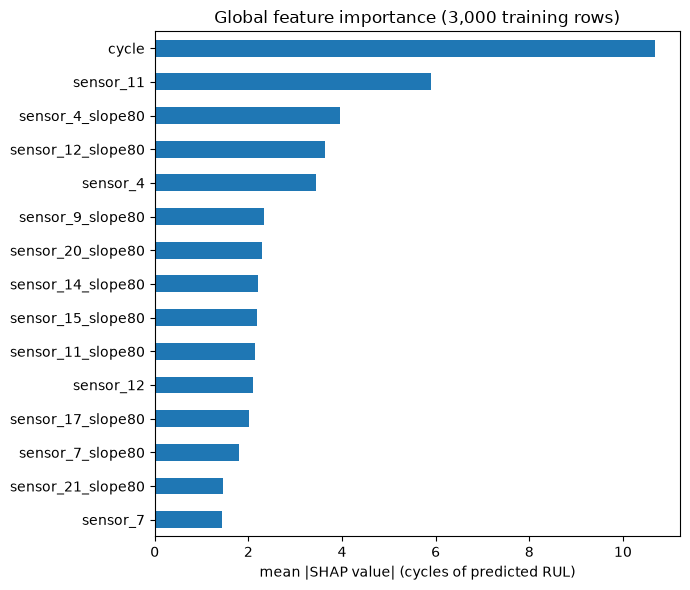

In [9]:
import shap

sample = X_train.sample(3000, random_state=42)
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(sample)

# Check: base value + sum of SHAP values should equal the model's prediction
recon = explainer.expected_value + sv.sum(axis=1)
print("Max difference between SHAP reconstruction and prediction:",
      float(np.abs(recon - model.predict(sample)).max()))

imp = pd.Series(np.abs(sv).mean(axis=0), index=sample.columns).sort_values(ascending=False)
print(imp.head(15).round(2))

fig, ax = plt.subplots(figsize=(7, 6))
imp.head(15).iloc[::-1].plot(kind="barh", ax=ax)
ax.set_xlabel("mean |SHAP value| (cycles of predicted RUL)")
ax.set_title("Global feature importance (3,000 training rows)")
plt.tight_layout()
plt.show()

Per-sensor total (raw + slope), mean |SHAP|:
cycle        10.68
sensor_11     8.05
sensor_4      7.39
sensor_12     5.72
sensor_7      3.23
sensor_15     3.01
sensor_20     2.78
sensor_9      2.71
sensor_14     2.45
sensor_17     2.28
sensor_21     1.96
sensor_13     1.95
sensor_2      1.88
sensor_8      1.35
sensor_3      1.14
dtype: float64

Share of total importance: cycle = 0.19 | slope features = 0.5


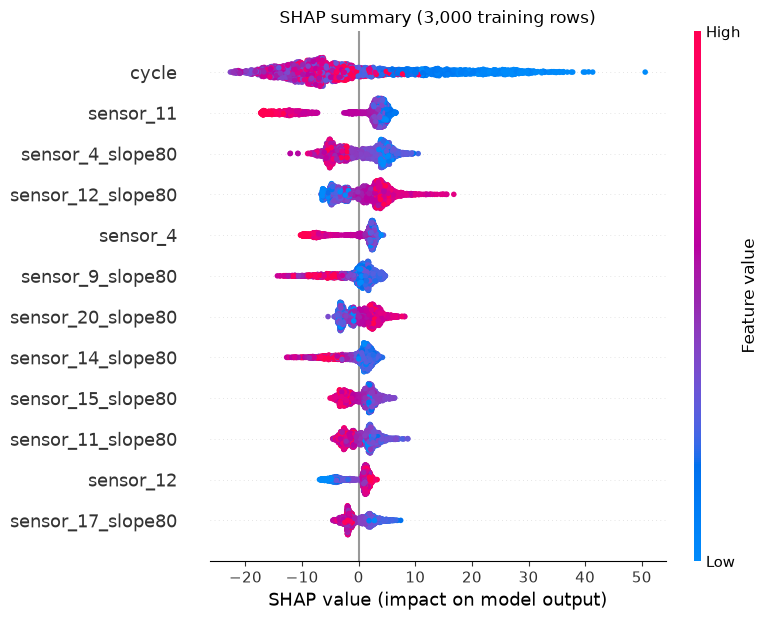

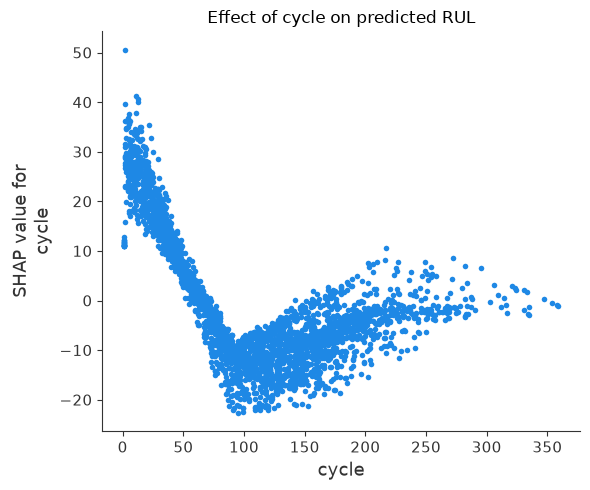

In [10]:
# 1. Combine each sensor's raw and slope contributions
by_sensor = {}
for c, v in imp.items():
    key = c.split("_slope")[0]
    by_sensor[key] = by_sensor.get(key, 0) + v
by_sensor = pd.Series(by_sensor).sort_values(ascending=False)
print("Per-sensor total (raw + slope), mean |SHAP|:")
print(by_sensor.round(2))
print("\nShare of total importance: cycle =", round(imp["cycle"] / imp.sum(), 2),
      "| slope features =", round(imp[[c for c in imp.index if "_slope" in c]].sum() / imp.sum(), 2))

# 2. Direction of effect: each dot is one row, colour = feature value
shap.summary_plot(sv, sample, max_display=12, show=False)
plt.title("SHAP summary (3,000 training rows)")
plt.tight_layout()
plt.show()

# 3. How cycle changes the prediction
shap.dependence_plot("cycle", sv, sample, interaction_index=None, show=False)
plt.title("Effect of cycle on predicted RUL")
plt.tight_layout()
plt.show()

In [11]:
X_last = X_test[is_last].reset_index(drop=True)
sv_last = explainer.shap_values(X_last)
base = float(explainer.expected_value)

for u in [67, 30]:
    i = last_units.index(u)
    contrib = pd.Series(sv_last[i], index=X_last.columns)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(6)
    print(f"Engine {u}: observed {int(X_last.loc[i, 'cycle'])} cycles, "
          f"true RUL {y_true[i]}, predicted {pred[i]:.1f}")
    print(f"  base value {base:.1f} + sum of all contributions {contrib.sum():+.1f} = {base + contrib.sum():.1f}")
    print("  top contributions (cycles):")
    print(top.round(1).to_string())
    print()

Engine 67: observed 71 cycles, true RUL 77, predicted 113.5
  base value 88.8 + sum of all contributions +24.7 = 113.5
  top contributions (cycles):
cycle               -5.2
sensor_11            4.0
sensor_7_slope80     3.5
sensor_4_slope80     3.4
sensor_17_slope80    2.9
sensor_20_slope80    2.6

Engine 30: observed 143 cycles, true RUL 115, predicted 82.3
  base value 88.8 + sum of all contributions -6.4 = 82.3
  top contributions (cycles):
cycle               -9.5
sensor_4_slope80    -6.2
sensor_12_slope80    4.1
sensor_17_slope80   -3.7
sensor_4             2.6
sensor_9_slope80     2.3



Correlation of error with total lifetime: -0.5
              n  mean_signed   MAE
life_bucket                       
(0, 177]     27          9.3  11.1
(177, 229]   48         -1.8   7.2
(229, 400]   25         -6.9  10.6


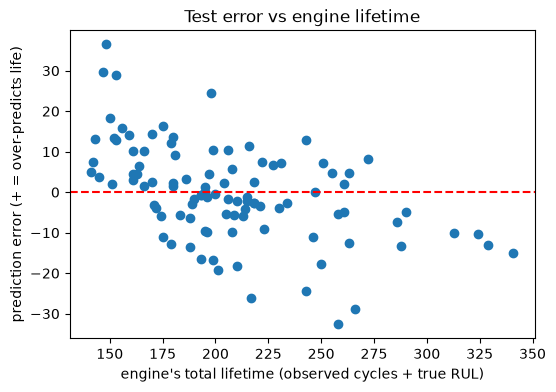

In [12]:
res["total_life"] = res["observed_cycles"] + res["true_RUL"]
print("Correlation of error with total lifetime:",
      round(res["error"].corr(res["total_life"]), 2))

res["life_bucket"] = pd.cut(res["total_life"], [0, 177, 229, 400])   # training quartile edges
print(res.groupby("life_bucket", observed=True)["error"]
         .agg(n="count", mean_signed="mean", MAE=lambda e: e.abs().mean()).round(1))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(res["total_life"], res["error"])
ax.axhline(0, color="red", linestyle="--")
ax.set_xlabel("engine's total lifetime (observed cycles + true RUL)")
ax.set_ylabel("prediction error (+ = over-predicts life)")
ax.set_title("Test error vs engine lifetime")
plt.show()

In [13]:
from sklearn.model_selection import GroupKFold

units = d_train["unit"].to_numpy()
true_rul = d_train["RUL"].to_numpy()
life = d_train.groupby("unit")["cycle"].transform("max").to_numpy()

def oof_predictions(X):
    oof = np.zeros(len(X))
    for tr, va in GroupKFold(n_splits=5).split(X, y_train, units):
        m = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                         subsample=0.8, colsample_bytree=0.8,
                         device="cuda", random_state=42)
        m.fit(X.iloc[tr], y_train.iloc[tr])
        oof[va] = m.predict(X.iloc[va])
    return oof

oof_with = oof_predictions(X_train)
oof_without = oof_predictions(X_train.drop(columns=["cycle"]))

keep = true_rul <= 145
bucket = pd.cut(life, [0, 177, 229, 400])           # training lifetime quartile edges
rows = []
for b in bucket.categories:
    m = keep & (bucket == b)
    rows.append({"lifetime bucket": str(b), "rows": int(m.sum()),
                 "bias with cycle": (oof_with[m] - true_rul[m]).mean(),
                 "bias without cycle": (oof_without[m] - true_rul[m]).mean(),
                 "MAE with cycle": np.abs(oof_with[m] - true_rul[m]).mean(),
                 "MAE without cycle": np.abs(oof_without[m] - true_rul[m]).mean()})
print(pd.DataFrame(rows).round(1).to_string(index=False))

lifetime bucket  rows  bias with cycle  bias without cycle  MAE with cycle  MAE without cycle
       (0, 177]  3603              6.8                 9.8             9.8               12.9
     (177, 229]  7300             -1.1                 1.5             7.0                8.1
     (229, 400]  3650             -4.0                -9.6             7.6               11.4
